# Libraries

In [1]:
import sklearn as sk
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from scipy.sparse import issparse
from sklearn.manifold import TSNE


# Global variables

In [2]:
target = "Diabetes_012"

# Helper Function

In [3]:
def divider():
    print("\n\n--------------------------------------------------------------------\n\n")

# Dataset Loading and Audit

No.of Rows: 236378
No.of Columns: 22


--------------------------------------------------------------------


Data types of columns:
Diabetes_012            float64
HighBP                    int64
HighChol                float64
CholCheck                 int64
BMI                     float64
Smoker                  float64
Stroke                  float64
HeartDiseaseorAttack    float64
PhysActivity              int64
Fruits                    int64
Veggies                   int64
HvyAlcoholConsump         int64
AnyHealthcare             int64
NoDocbcCost             float64
GenHlth                 float64
MentHlth                float64
PhysHlth                float64
DiffWalk                float64
Sex                       int64
Age                       int64
Education               float64
Income                  float64
dtype: object


--------------------------------------------------------------------


No.of null values per column:
Diabetes_012            0
HighBP              

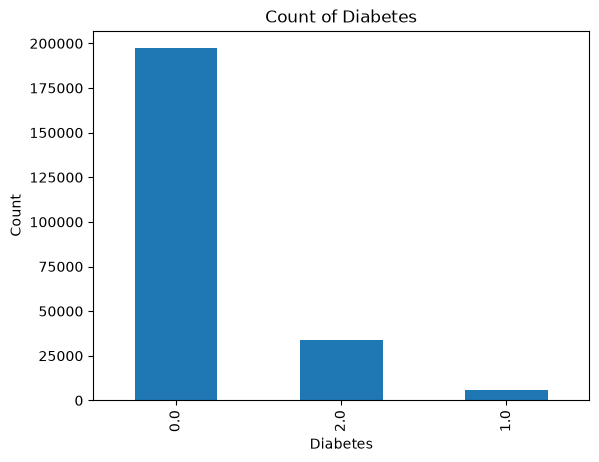

In [4]:
df = pd.read_csv("../data/clustering.csv")
print(f"No.of Rows: {df.shape[0]}")
print(f"No.of Columns: {df.shape[1]}")
divider()
print("Data types of columns:")
print(df.dtypes)
divider()
print("No.of null values per column:")
print(df.isna().sum())
divider()

df["Diabetes_012"].value_counts().plot(kind="bar")
print("0: No diabetes\n1: Pre-diabetes\n2: Diabetes")
plt.xlabel("Diabetes")
plt.ylabel("Count")
plt.title("Count of Diabetes")
plt.show()

# EDA

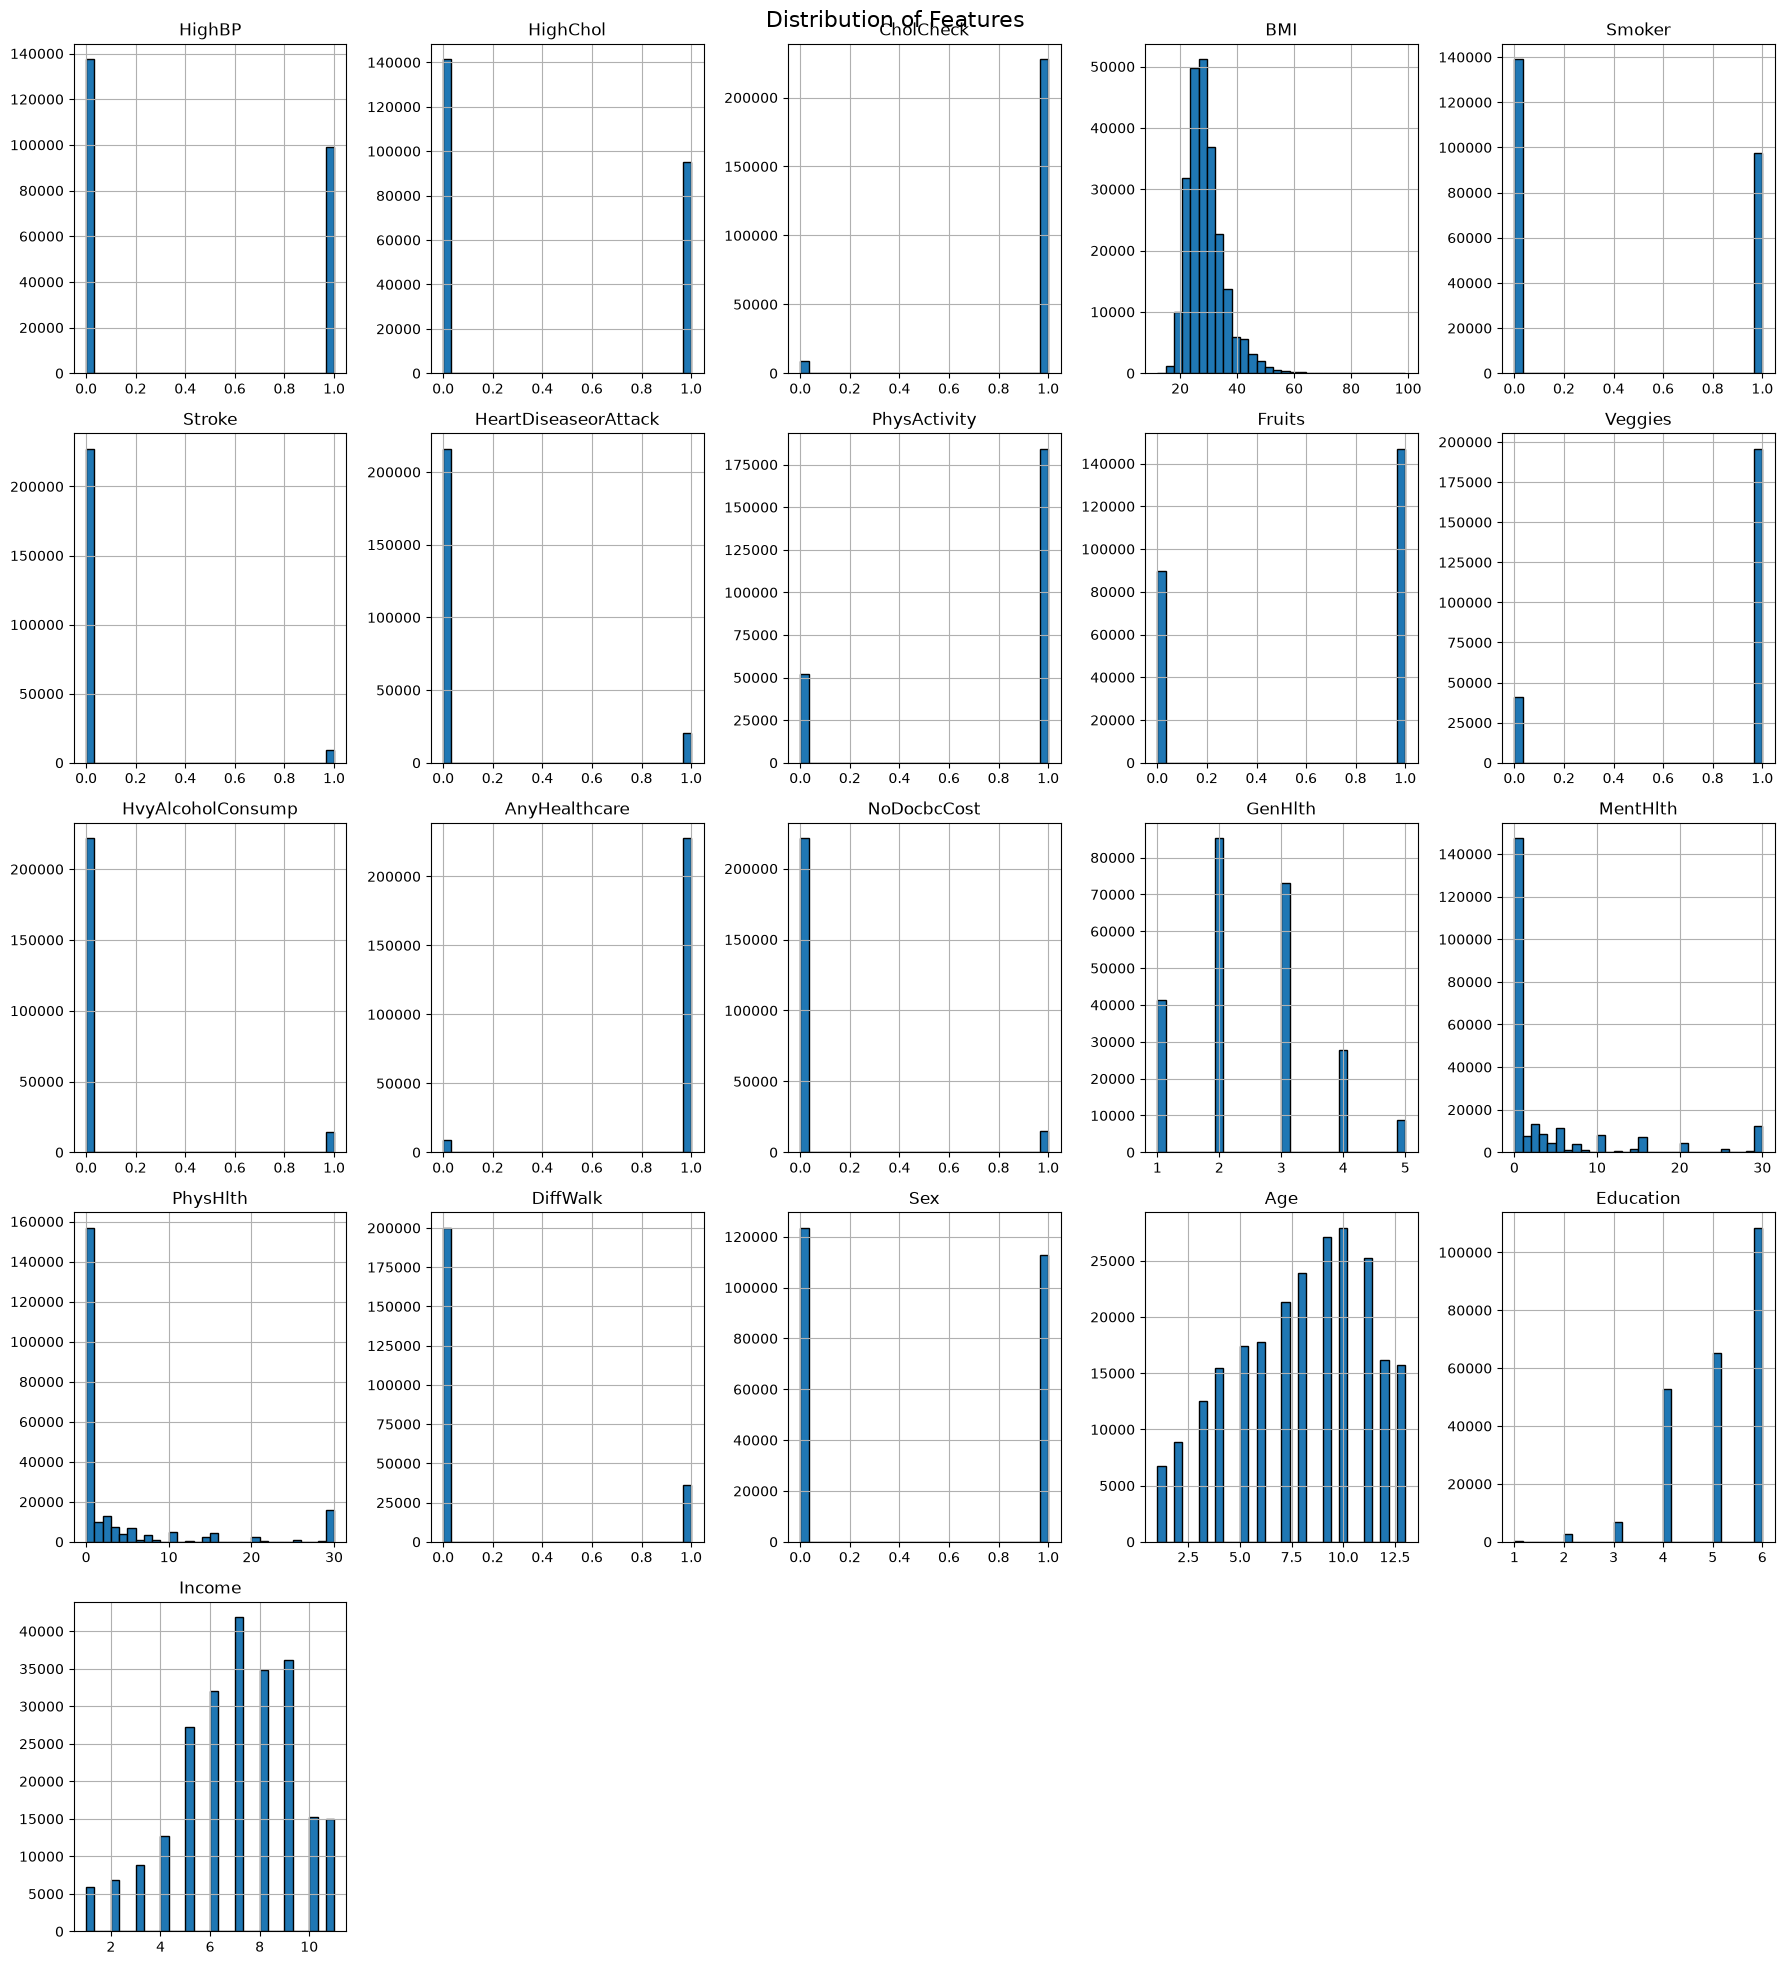



--------------------------------------------------------------------




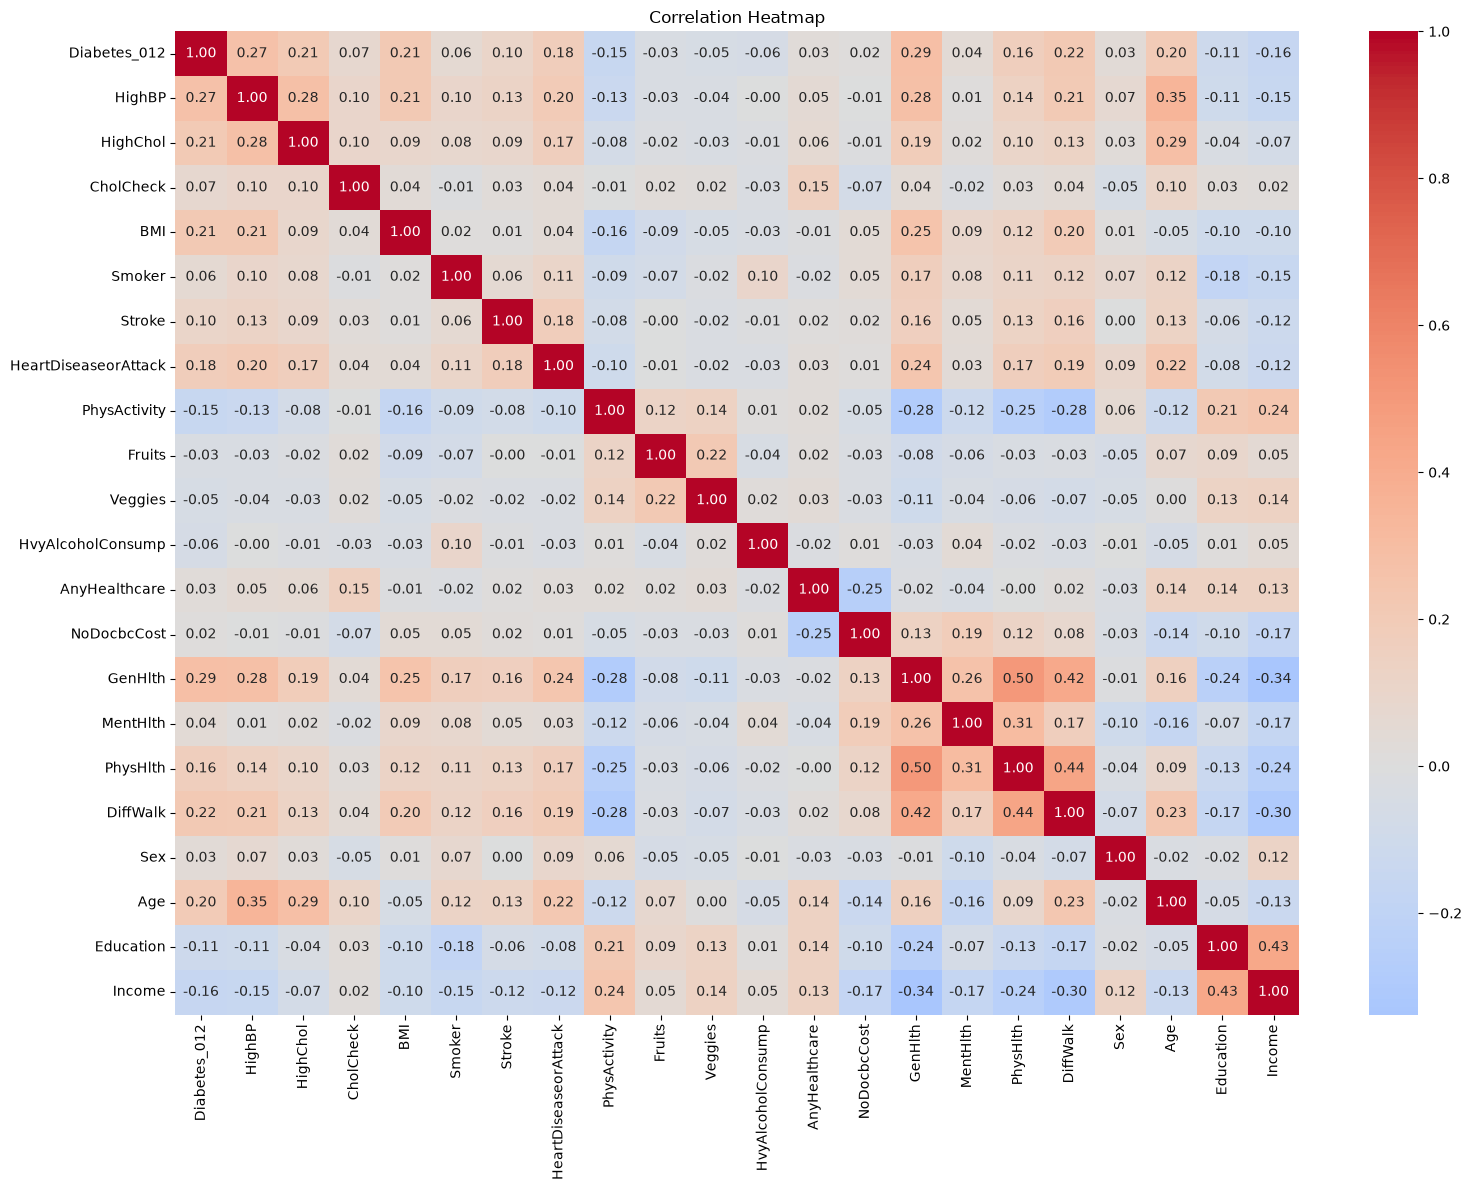



--------------------------------------------------------------------




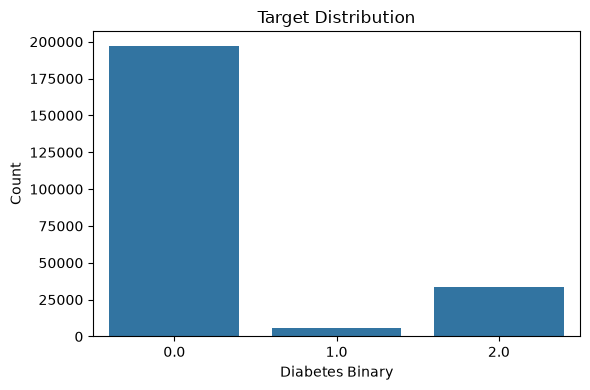



--------------------------------------------------------------------




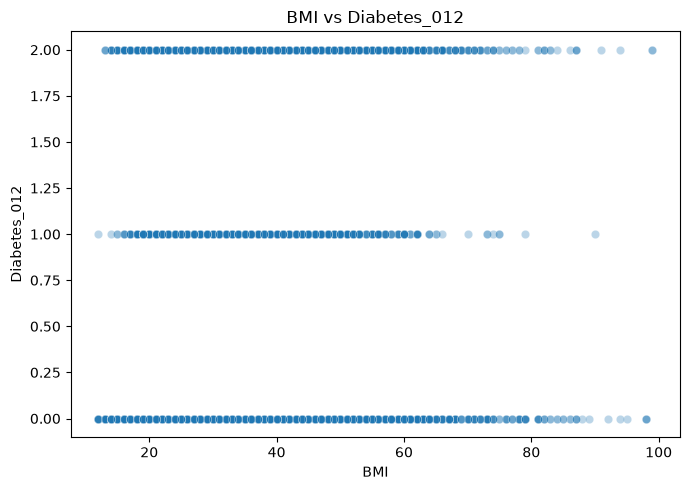

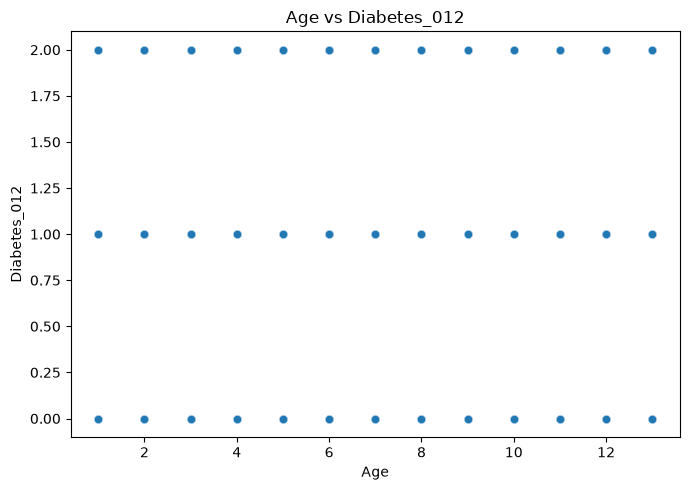

In [5]:
X = df.drop(columns=[target])
y = df[target]


# --------------------------------------------------
# 1. Distribution plots for each feature
# --------------------------------------------------

X.hist(
    bins=30,
    figsize=(18, 20),
    edgecolor="black"
)

plt.suptitle("Distribution of Features", fontsize=16)
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 2. Correlation heatmap
# --------------------------------------------------

plt.figure(figsize=(16, 12))

sns.heatmap(
    df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 3. Target distribution
# --------------------------------------------------

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x=target
)

plt.title("Target Distribution")
plt.xlabel("Diabetes Binary")
plt.ylabel("Count")
plt.tight_layout()
plt.show()
divider()

# --------------------------------------------------
# 4. Feature-target scatter plots
# --------------------------------------------------

feature1 = "BMI"
feature2 = "Age"

plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x=feature1,
    y=target,
    alpha=0.3
)

plt.title(f"{feature1} vs {target}")
plt.xlabel(feature1)
plt.ylabel(target)
plt.tight_layout()
plt.show()


plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x=feature2,
    y=target,
    alpha=0.3
)

plt.title(f"{feature2} vs {target}")
plt.xlabel(feature2)
plt.ylabel(target)
plt.tight_layout()
plt.show()

### Interpretation
- The first thing we can see is that the target variable is completely unbalanced.
- Most features are not correlated.
- Some features kinda follow a skewed normal distribution.

# Data cleaning

In [6]:

print("Missing values:")
# Check missing values in each column
print(df.isnull().sum())
divider()

print("Percentage of missing values:")
# Check percentage of missing values
print(df.isnull().mean() * 100)
divider()


# Handle missing values
for col in df.columns:
    if df[col].dtype in ["int64", "float64"]:
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])


print("After handling missing values:")
print(df.isnull().sum())
divider()

# Count duplicate rows
print("Duplicate rows count:", df.duplicated().sum())
divider()

print("Duplicated rows:")
# Display duplicate rows
print(df[df.duplicated()])
divider()

# Remove duplicate rows, keeping the first occurrence
df = df.drop_duplicates()

print("Duplicates after removal:", df.duplicated().sum())

"""
divider()
print("Target distribution after balancing:")
min_count = df[target].value_counts().min()

df = (
    df.groupby(target)
      .sample(n=min_count, random_state=42)
      .reset_index(drop=True)
)
print(df[target].value_counts())
"""

Missing values:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


--------------------------------------------------------------------


Percentage of missing values:
Diabetes_012            0.0
HighBP                  0.0
HighChol                0.0
CholCheck               0.0
BMI                     0.0
Smoker                  0.0
Stroke                  0.0
HeartDiseaseorAttack    0.0
PhysActivity            0.0
Fruits                  0.0
Veggies         

'\ndivider()\nprint("Target distribution after balancing:")\nmin_count = df[target].value_counts().min()\n\ndf = (\n    df.groupby(target)\n      .sample(n=min_count, random_state=42)\n      .reset_index(drop=True)\n)\nprint(df[target].value_counts())\n'

# Encoding, scaling & splitting

In [7]:
# Separate features and known labels
X = df.drop(columns=[target])
y = df[target]  # Used only for evaluation

# 2. Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

# 3. train/test split
X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Preprocessing
# Scale numerical features and one-hot encode categoricals
str_preprocessor = Pipeline([
    ('encode', OneHotEncoder(handle_unknown="ignore")),
    ('scale', StandardScaler()) 
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", str_preprocessor, cat_cols)
    ]
)

# Fit only on training features
X_train_scaled = preprocessor.fit_transform(X_train)

# Transform test features using training-fitted parameters
X_test_scaled = preprocessor.transform(X_test)


Numerical columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Categorical columns: []


# Feature engineering

In [8]:
# 5. Remove highly correlated features


# Convert to dense arrays for correlation calculation
X_train_dense = (
    X_train_scaled.toarray()
    if issparse(X_train_scaled)
    else X_train_scaled
)

X_test_dense = (
    X_test_scaled.toarray()
    if issparse(X_test_scaled)
    else X_test_scaled
)

# Calculate correlation matrix using training data only
corr_matrix = pd.DataFrame(X_train_dense).corr().abs()

# Get upper triangle of correlation matrix
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Identify features with correlation above 0.90
threshold = 0.90
to_drop = [
    column
    for column in upper.columns
    if any(upper[column] > threshold)
]

# Keep the same columns in both datasets
keep_cols = [
    i for i in range(X_train_dense.shape[1])
    if i not in to_drop
]

X_train_scaled = X_train_dense[:, keep_cols]
X_test_scaled = X_test_dense[:, keep_cols]

print("Original number of features:", len(num_cols) + len(cat_cols))
print("Features removed:", len(to_drop))
print("Features remaining:", X_train_scaled.shape[1])
print("Training shape:", X_train_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

X = X_train_scaled
X_test = X_test_scaled

Original number of features: 21
Features removed: 0
Features remaining: 21
Training shape: (178840, 21)
Testing shape: (44710, 21)


# K-Means Clustering


K-Means Results for Different Values of k
 k      Inertia  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
 2 3371527.4839            0.1828                2.6910                2237.5740
 3 3186718.8343            0.1837                2.5304                1760.3362
 4 3014949.2816            0.0751                2.7004                1611.9894
 5 2861375.7235            0.0849                2.4165                1546.4005
 6 2748088.0268            0.0882                2.3312                1463.9514
 7 2629336.4898            0.0959                2.1596                1413.5425
 8 2508828.3739            0.0990                2.1112                1409.0508
 9 2439895.9277            0.0984                2.1649                1340.6951
10 2368508.6481            0.0805                2.2312                1295.7200


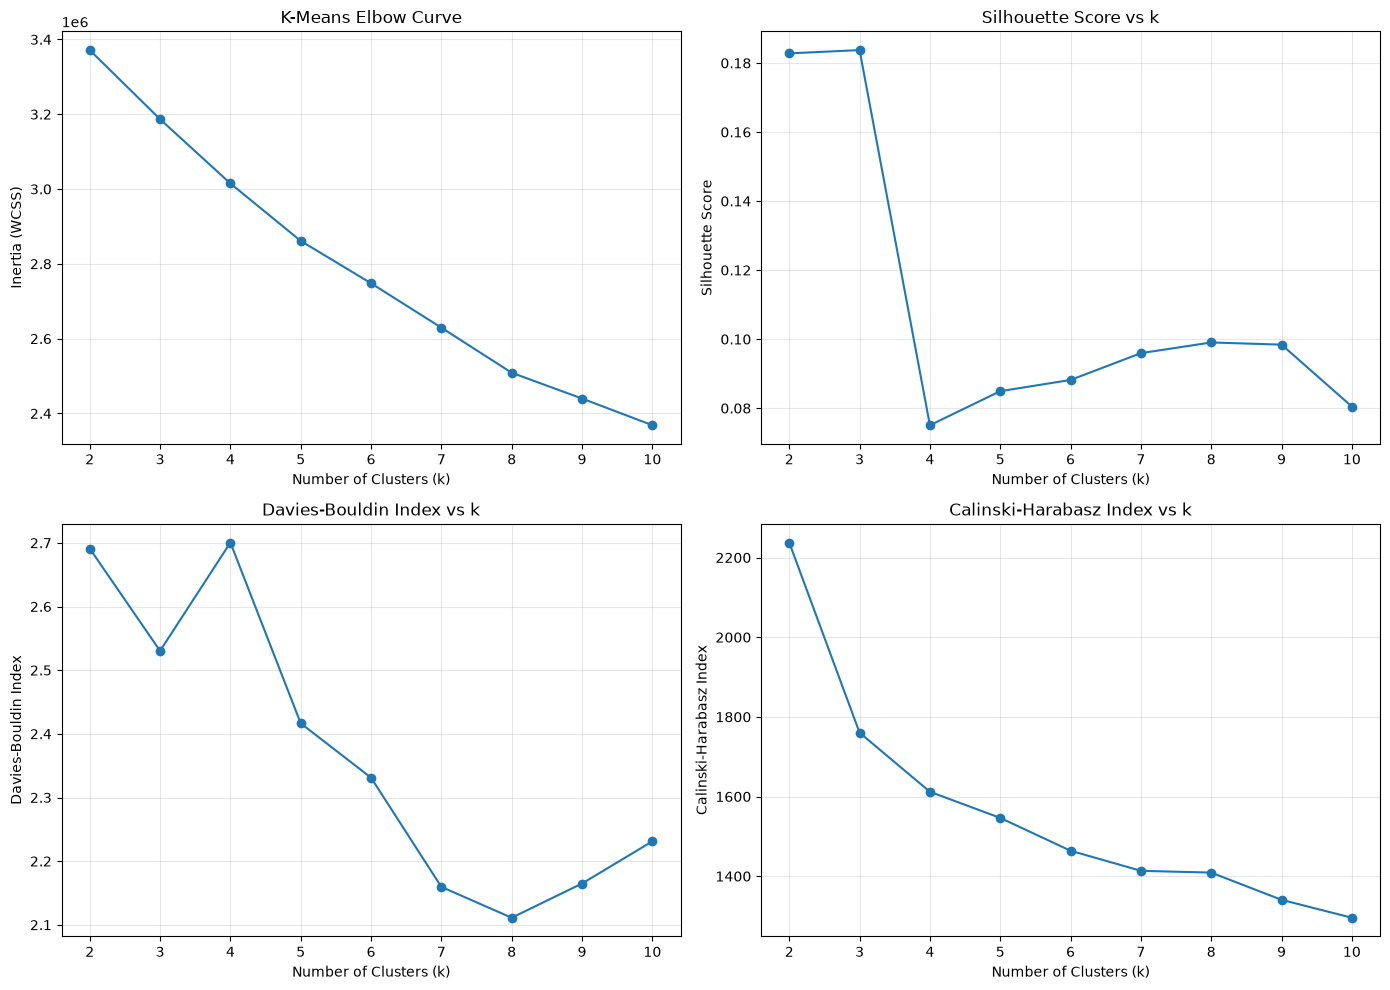


Chosen k: 3
Cluster labels: [0 1 2]
Cluster sizes: [120290  18007  40543]
Full-data inertia: 3186718.8343

Final K-Means Evaluation Metrics
                 Metric     Score
       Silhouette Score    0.1837
   Davies-Bouldin Index    2.5304
Calinski-Harabasz Index 1760.3362


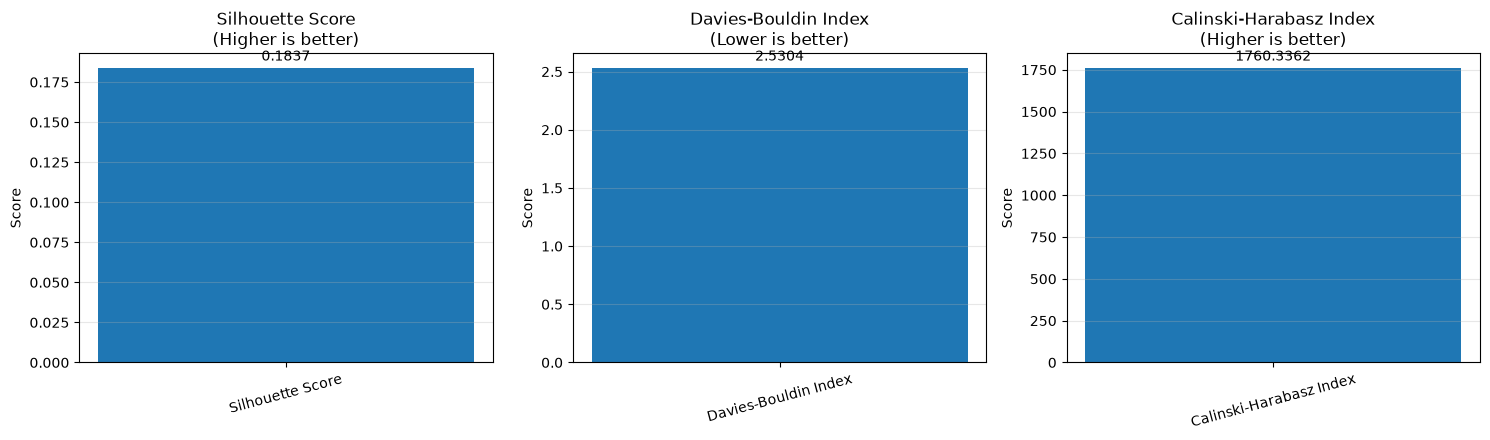

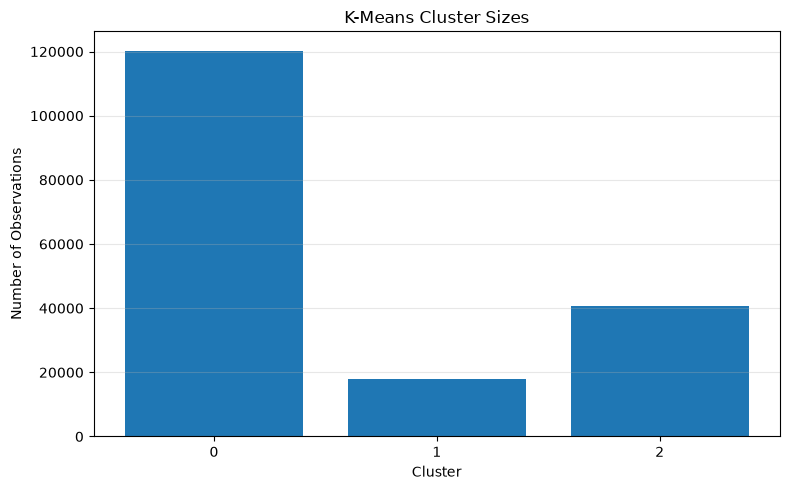

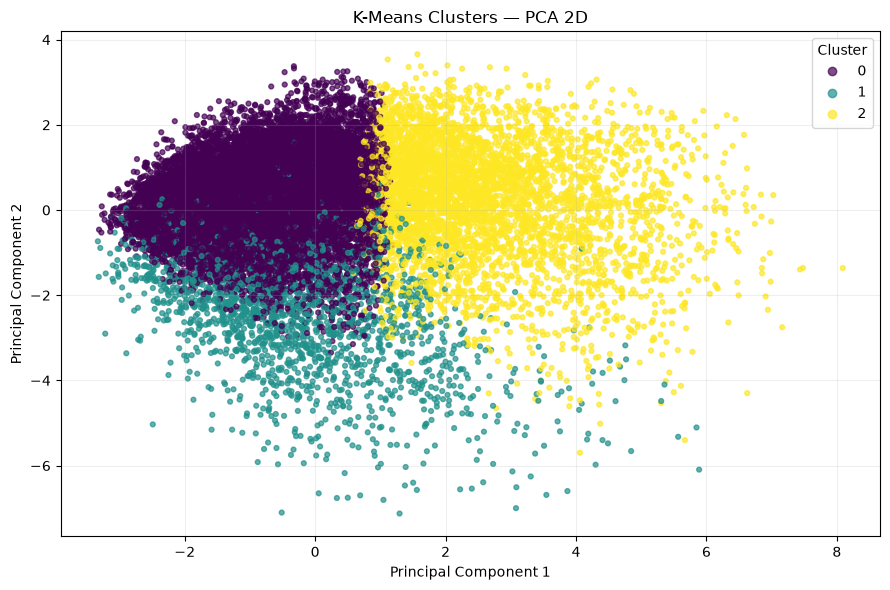

PCA variance explained: 24.06 %


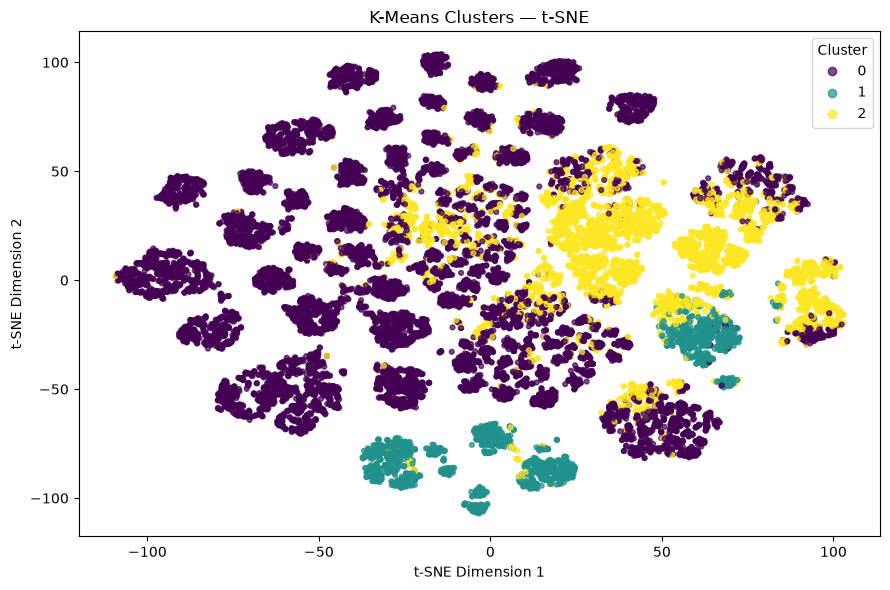

In [9]:


# ==========================================
# 1. PREPARE DATA
# ==========================================
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)
X_array = np.asarray(X_array, dtype=np.float64)

rng = np.random.default_rng(42)
sample_size = min(20000, len(X_array))
sample_idx = np.sort(
    rng.choice(len(X_array), sample_size, replace=False)
)
X_compare = X_array[sample_idx]

# ==========================================
# 2. ELBOW CURVE + ALL THREE METRICS
# ==========================================
k_values = list(range(2, min(11, len(X_array))))
inertias = []
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit K-Means on the full dataset
    labels = model.fit_predict(X_array)

    inertias.append(model.inertia_)

    # Evaluate on the same fixed sample for every k
    sample_labels_k = labels[sample_idx]

    silhouette_scores.append(
        silhouette_score(X_compare, sample_labels_k)
    )

    davies_bouldin_scores.append(
        davies_bouldin_score(X_compare, sample_labels_k)
    )

    calinski_harabasz_scores.append(
        calinski_harabasz_score(X_compare, sample_labels_k)
    )

# Combine results into a table
k_results = pd.DataFrame({
    "k": k_values,
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores,
    "Davies-Bouldin Index": davies_bouldin_scores,
    "Calinski-Harabasz Index": calinski_harabasz_scores
})

print("\nK-Means Results for Different Values of k")
print(k_results.round(4).to_string(index=False))

# ==========================================
# 3. PLOT ELBOW AND THREE METRICS
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Elbow curve
axes[0, 0].plot(k_values, inertias, marker="o")
axes[0, 0].set_title("K-Means Elbow Curve")
axes[0, 0].set_xlabel("Number of Clusters (k)")
axes[0, 0].set_ylabel("Inertia (WCSS)")
axes[0, 0].set_xticks(k_values)
axes[0, 0].grid(True, alpha=0.3)

# Silhouette Score: higher is better
axes[0, 1].plot(
    k_values, silhouette_scores, marker="o"
)
axes[0, 1].set_title("Silhouette Score vs k")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Silhouette Score")
axes[0, 1].set_xticks(k_values)
axes[0, 1].grid(True, alpha=0.3)

# Davies-Bouldin Index: lower is better
axes[1, 0].plot(
    k_values, davies_bouldin_scores, marker="o"
)
axes[1, 0].set_title("Davies-Bouldin Index vs k")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("Davies-Bouldin Index")
axes[1, 0].set_xticks(k_values)
axes[1, 0].grid(True, alpha=0.3)

# Calinski-Harabasz Index: higher is better
axes[1, 1].plot(
    k_values, calinski_harabasz_scores, marker="o"
)
axes[1, 1].set_title("Calinski-Harabasz Index vs k")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Calinski-Harabasz Index")
axes[1, 1].set_xticks(k_values)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# 4. SELECT k AND FIT FINAL K-MEANS
# ==========================================
# Choose after inspecting the elbow and metrics
chosen_k = 3

kmeans = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_array)
sample_labels = kmeans_labels[sample_idx]

print("\nChosen k:", chosen_k)
print("Cluster labels:", np.unique(kmeans_labels))
print("Cluster sizes:", np.bincount(kmeans_labels))
print("Full-data inertia:", round(kmeans.inertia_, 4))

# ==========================================
# 5. FINAL EVALUATION METRICS
# ==========================================
final_metrics = {
    "Silhouette Score": silhouette_score(
        X_compare, sample_labels
    ),
    "Davies-Bouldin Index": davies_bouldin_score(
        X_compare, sample_labels
    ),
    "Calinski-Harabasz Index": calinski_harabasz_score(
        X_compare, sample_labels
    )
}

metrics_df = pd.DataFrame(
    list(final_metrics.items()),
    columns=["Metric", "Score"]
)

print("\nFinal K-Means Evaluation Metrics")
print(metrics_df.round(4).to_string(index=False))

# ==========================================
# 6. PLOT FINAL METRICS SEPARATELY
# ==========================================
# Separate plots prevent the different score scales from distorting the visual comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metric_info = [
    ("Silhouette Score", "Higher is better"),
    ("Davies-Bouldin Index", "Lower is better"),
    ("Calinski-Harabasz Index", "Higher is better")
]

for ax, (metric, direction) in zip(axes, metric_info):
    value = final_metrics[metric]

    ax.bar([metric], [value])
    ax.set_title(f"{metric}\n({direction})")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", labelrotation=15)
    ax.grid(axis="y", alpha=0.3)

    # Label the bar with its value
    ax.bar_label(
        ax.containers[0],
        fmt="%.4f",
        padding=3
    )

plt.tight_layout()
plt.show()

# ==========================================
# 7. CLUSTER SIZE VISUALIZATION
# ==========================================
cluster_ids, cluster_counts = np.unique(
    kmeans_labels, return_counts=True
)

plt.figure(figsize=(8, 5))
plt.bar(cluster_ids, cluster_counts)
plt.xlabel("Cluster")
plt.ylabel("Number of Observations")
plt.title("K-Means Cluster Sizes")
plt.xticks(cluster_ids)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 8. PCA 2D VISUALIZATION
# ==========================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Clusters — PCA 2D")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ==========================================
# 9. t-SNE VISUALIZATION
# ==========================================
tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(X_compare) - 1) / 3),
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_compare)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=sample_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("K-Means Clusters — t-SNE")
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.tight_layout()
plt.show()


# Agglomerative Hierarchical Clustering


Testing linkage: single

Testing linkage: complete

Testing linkage: average

Testing linkage: ward

ALL AGGLOMERATIVE CLUSTERING RESULTS
 Linkage  k  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
  single  2            0.5478                0.3310                   8.2903
  single  3            0.4862                0.3635                   7.2979
  single  4            0.4748                0.3659                   7.0409
  single  5            0.4687                0.3685                   6.8623
  single  6            0.4662                0.3683                   6.8359
  single  7            0.4480                0.3781                   6.6066
  single  8            0.4009                0.3925                   6.3027
  single  9            0.3911                0.3979                   6.1001
  single 10            0.3822                0.4017                   5.9531
complete  2            0.2527                1.8634                 167.4262
complete  3   

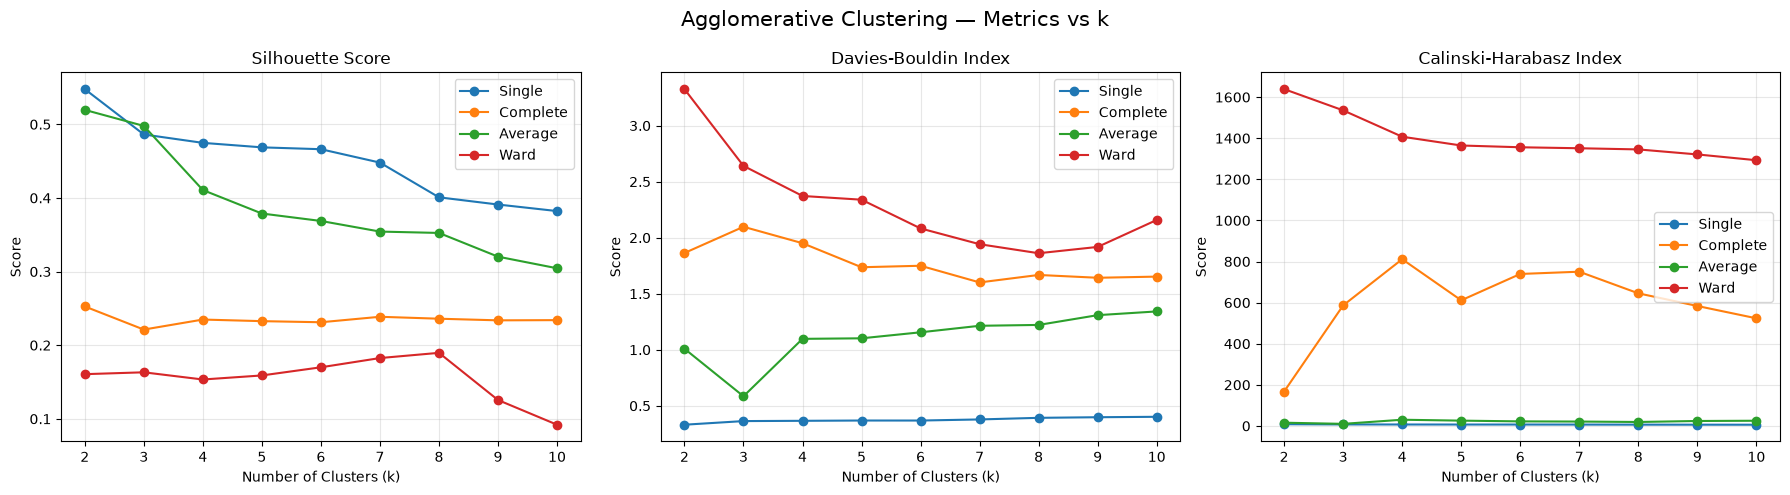


BEST k FOR EACH LINKAGE
 Linkage  k  Silhouette Score  Davies-Bouldin Index  Calinski-Harabasz Index
  single  2            0.5478                0.3310                   8.2903
 average  2            0.5196                1.0093                  15.7174
complete  2            0.2527                1.8634                 167.4262
    ward  8            0.1896                1.8613                1345.4913

SELECTED MODEL
Linkage: single
Chosen k: 2
Silhouette Score: 0.5478
Davies-Bouldin Index: 0.331
Calinski-Harabasz Index: 8.2903

Selected model cluster sizes:
(array([0, 1]), array([19999,     1]))


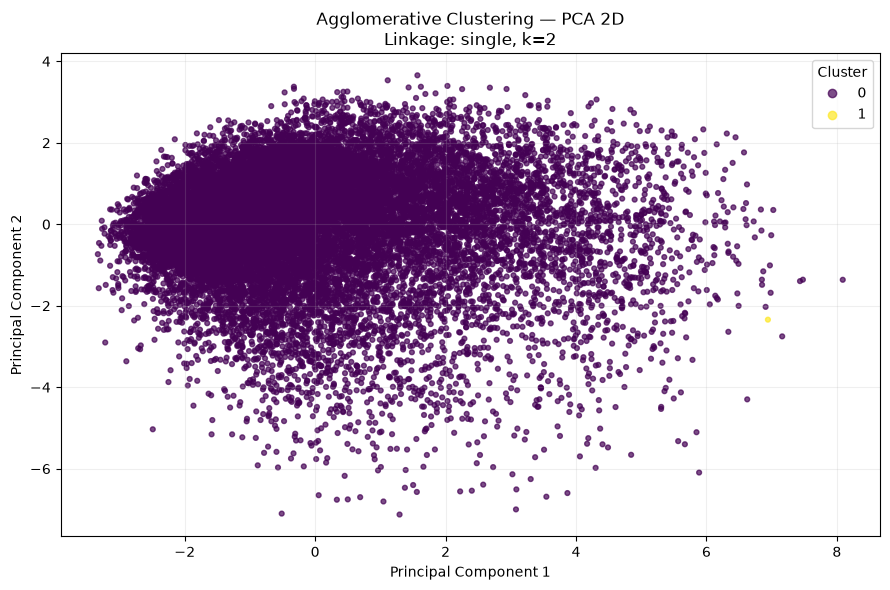

PCA variance explained: 24.06 %


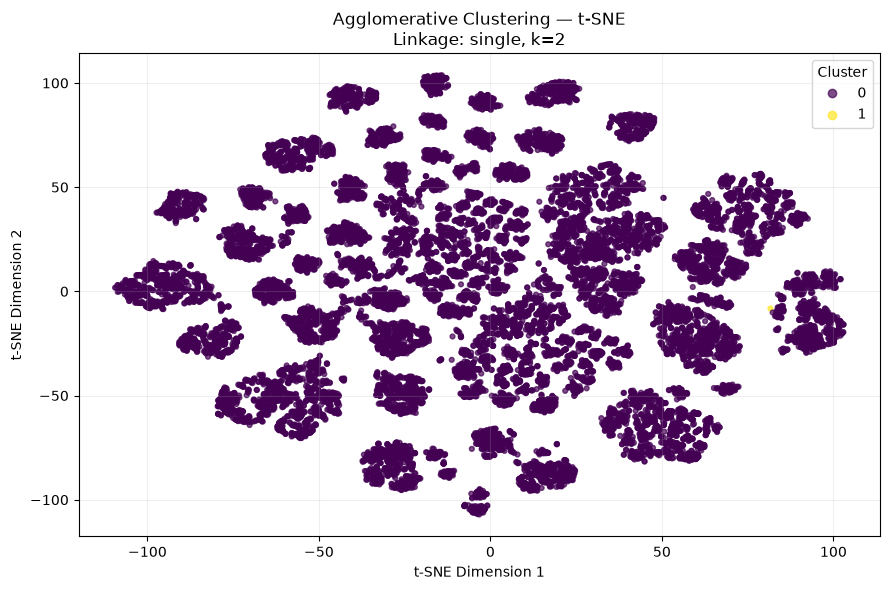

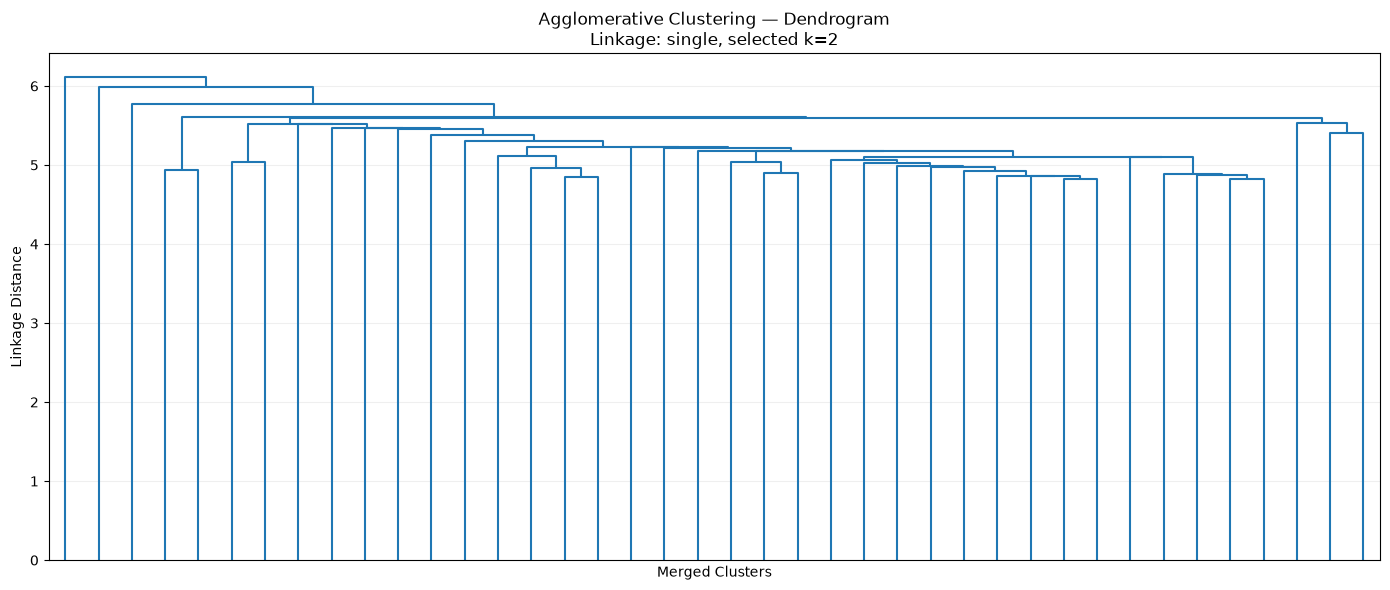

In [10]:


# ==========================================
# 1. PREPARE DATA
# ==========================================
X_array = X.to_numpy() if hasattr(X, "to_numpy") else np.asarray(X)
X_array = np.asarray(X_array, dtype=np.float64)

if not np.isfinite(X_array).all():
    raise ValueError("Clean missing and infinite values in X first.")

if len(X_array) < 3:
    raise ValueError("At least 3 observations are required.")

rng = np.random.default_rng(42)

sample_size = min(20000, len(X_array))
sample_idx = np.sort(
    rng.choice(len(X_array), sample_size, replace=False)
)
X_compare = X_array[sample_idx]

linkage_methods = ["single", "complete", "average", "ward"]

# ==========================================
# 2. TEST MULTIPLE k VALUES FOR EACH LINKAGE
# ==========================================
k_values = range(2, 11)

agg_labels = {}
results = []

for method in linkage_methods:
    print(f"\nTesting linkage: {method}")

    for k in k_values:
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method,
            metric="euclidean"
        )

        labels = model.fit_predict(X_compare)
        n_clusters = len(np.unique(labels))

        # Skip invalid clustering results
        if not (1 < n_clusters < len(X_compare)):
            continue

        sil = silhouette_score(X_compare, labels)
        dbi = davies_bouldin_score(X_compare, labels)
        chi = calinski_harabasz_score(X_compare, labels)

        results.append({
            "Linkage": method,
            "k": k,
            "Silhouette Score": sil,
            "Davies-Bouldin Index": dbi,
            "Calinski-Harabasz Index": chi
        })

# ==========================================
# 3. DISPLAY ALL RESULTS
# ==========================================
agg_metrics = pd.DataFrame(results)

print("\nALL AGGLOMERATIVE CLUSTERING RESULTS")
print(agg_metrics.round(4).to_string(index=False))

# ==========================================
# 4. PLOT ALL THREE METRICS AGAINST k
# ==========================================
metric_columns = [
    "Silhouette Score",
    "Davies-Bouldin Index",
    "Calinski-Harabasz Index"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric in zip(axes, metric_columns):
    for method in linkage_methods:
        subset = agg_metrics[
            agg_metrics["Linkage"] == method
        ]

        ax.plot(
            subset["k"],
            subset[metric],
            marker="o",
            label=method.capitalize()
        )

    ax.set_title(metric)
    ax.set_xlabel("Number of Clusters (k)")
    ax.set_ylabel("Score")
    ax.set_xticks(list(k_values))
    ax.grid(True, alpha=0.3)
    ax.legend()

fig.suptitle(
    "Agglomerative Clustering — Metrics vs k",
    fontsize=15
)
plt.tight_layout()
plt.show()

# ==========================================
# 5. AUTOMATICALLY SELECT BEST k PER LINKAGE
# ==========================================
# Primary selection criterion: highest Silhouette Score
best_rows = (
    agg_metrics.loc[
        agg_metrics.groupby("Linkage")["Silhouette Score"].idxmax()
    ]
    .sort_values("Silhouette Score", ascending=False)
    .reset_index(drop=True)
)

print("\nBEST k FOR EACH LINKAGE")
print(best_rows.round(4).to_string(index=False))

# Overall best combination
best_overall = best_rows.iloc[0]

chosen_linkage = best_overall["Linkage"]
chosen_k = int(best_overall["k"])

print("\nSELECTED MODEL")
print("Linkage:", chosen_linkage)
print("Chosen k:", chosen_k)
print("Silhouette Score:", round(
    best_overall["Silhouette Score"], 4
))
print("Davies-Bouldin Index:", round(
    best_overall["Davies-Bouldin Index"], 4
))
print("Calinski-Harabasz Index:", round(
    best_overall["Calinski-Harabasz Index"], 4
))

# ==========================================
# 6. FIT THE SELECTED MODEL
# ==========================================
best_model = AgglomerativeClustering(
    n_clusters=chosen_k,
    linkage=chosen_linkage,
    metric="euclidean"
)

best_labels = best_model.fit_predict(X_compare)

print("\nSelected model cluster sizes:")
print(np.unique(best_labels, return_counts=True))


# ==========================================
# 7. PCA 2D VISUALIZATION
# ==========================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_compare)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=best_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(
    f"Agglomerative Clustering — PCA 2D\n"
    f"Linkage: {chosen_linkage}, k={chosen_k}"
)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "PCA variance explained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ==========================================
# 8. t-SNE VISUALIZATION
# ==========================================
tsne = TSNE(
    n_components=2,
    perplexity=min(30, (len(X_compare) - 1) / 3),
    init="pca",
    learning_rate="auto",
    random_state=42
)

X_tsne = tsne.fit_transform(X_compare)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=best_labels,
    cmap="viridis",
    s=12,
    alpha=0.7
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title(
    f"Agglomerative Clustering — t-SNE\n"
    f"Linkage: {chosen_linkage}, k={chosen_k}"
)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

# ==========================================
# 9. DENDROGRAM
# ==========================================
# Dendrograms are expensive on large datasets.
# Use a subset of up to 1,000 observations.
dendrogram_rows = min(1000, len(X_compare))

dendrogram_idx = np.sort(
    rng.choice(
        len(X_compare),
        dendrogram_rows,
        replace=False
    )
)

X_dendro = X_compare[dendrogram_idx]

Z = linkage(
    X_dendro,
    method=chosen_linkage,
    metric="euclidean"
)

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=40,
    show_leaf_counts=True,
    no_labels=True
)

plt.title(
    f"Agglomerative Clustering — Dendrogram\n"
    f"Linkage: {chosen_linkage}, selected k={chosen_k}"
)
plt.xlabel("Merged Clusters")
plt.ylabel("Linkage Distance")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()